<a href="https://colab.research.google.com/github/Nilamsari01/Pengolahan_Citra_Digital/blob/main/F1G124046_NILAM_SARI_Pertemuan11_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 11 — Restorasi Citra
**Pengolahan Citra Digital · MK36 · Ilmu Komputer FMIPA Universitas Halu Oleo**

Model degradasi, imaging difraksi sirkular, image motion blur, photographic recording model, serta restorasi dengan filter inverse dan Wiener.

**Cara memakai di Google Colab**
1. Buka [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** → pilih file ini.
2. Pilih **Runtime → Run all**, atau jalankan sel berurutan dari atas (`Shift + Enter`).
3. Ingin memakai citra sendiri? Di sel **Citra**, ubah `PAKAI_CITRA_SENDIRI = True`, lalu pilih file saat diminta.

Nomor slide dicantumkan di setiap judul bagian.

## Setup: fungsi bantu restorasi (slide 4)
NumPy, OpenCV, dan Matplotlib sudah tersedia di Colab — tidak perlu `pip install`.

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100


def frek_terpusat(M, N):
    """Koordinat frekuensi terpusat: U (baris) dan V (kolom), DC di (M//2, N//2)."""
    u = np.arange(M) - M // 2
    v = np.arange(N) - N // 2
    V, U = np.meshgrid(v, u)
    return U, V

def jarak(M, N):
    """D(u,v): jarak tiap titik ke pusat spektrum (sama seperti minggu 9–10)."""
    U, V = frek_terpusat(M, N)
    return np.sqrt(U**2 + V**2)

def degradasi(f, H, sigma=0.0, seed=0):
    """Model degradasi g = h ⋆ f + η  ⇔  G = H·F + N  (H terpusat, noise Gaussian σ)."""
    F = np.fft.fftshift(np.fft.fft2(f))
    g = np.real(np.fft.ifft2(np.fft.ifftshift(H * F)))
    return g + np.random.default_rng(seed).normal(0, sigma, f.shape)

def restorasi(g, R):
    """F̂ = R · G, dengan R filter restorasi terpusat."""
    G = np.fft.fftshift(np.fft.fft2(g))
    return np.real(np.fft.ifft2(np.fft.ifftshift(R * G)))

def psnr(asli, uji, maks=255.0):
    """Peak signal-to-noise ratio (dB): makin besar makin mirip citra asli."""
    mse = np.mean((asli.astype(float) - uji.astype(float)) ** 2)
    return 10 * np.log10(maks**2 / mse)

def spektrum(a):
    """Spektrum magnitude terpusat dalam skala log."""
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(a))))

def tampilkan(gambar, judul, ukuran=3.2, rentang=(0, 255)):
    """Tampilkan beberapa citra berdampingan (rentang=None → skala otomatis)."""
    vmin, vmax = rentang if rentang else (None, None)
    plt.figure(figsize=(ukuran * len(gambar), ukuran))
    for i, (g, j) in enumerate(zip(gambar, judul)):
        plt.subplot(1, len(gambar), i + 1)
        plt.imshow(g, cmap='gray', vmin=vmin, vmax=vmax); plt.title(j, fontsize=10); plt.axis('off')
    plt.tight_layout(); plt.show()

## Citra
Sel ini membuat citra contoh `citra.jpg`. Ubah `PAKAI_CITRA_SENDIRI = True` untuk mengunggah citra Anda (dikecilkan ke sisi maksimum 512 piksel).

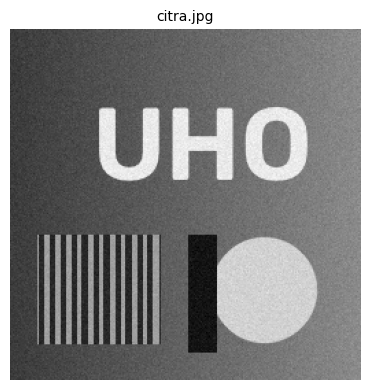

In [38]:
PAKAI_CITRA_SENDIRI = False      # ubah ke True untuk mengunggah citra sendiri
UKURAN = 256


def citra_1():
    """Latar gradasi + teks + bentuk + tekstur garis + sedikit noise."""
    baris, kol = np.indices((UKURAN, UKURAN))
    img = 60 + 80 * kol / UKURAN
    img[150:230, 20:110] = 40 + 30 * (np.sin(2 * np.pi * kol[150:230, 20:110] / 8) > 0) * 4
    img = img.astype(np.uint8)
    cv2.putText(img, 'UHO', (60, 110), cv2.FONT_HERSHEY_SIMPLEX, 2.6, 235, 8, cv2.LINE_AA)
    cv2.circle(img, (185, 190), 38, 210, -1, cv2.LINE_AA)
    cv2.rectangle(img, (130, 150), (150, 235), 20, -1)
    rng = np.random.default_rng(9)
    return np.clip(img + rng.normal(0, 6, img.shape), 0, 255).astype(np.uint8)


def unggah_citra():
    from google.colab import files
    hasil = files.upload()
    nama = next(iter(hasil))
    c = cv2.imdecode(np.frombuffer(hasil[nama], np.uint8), cv2.IMREAD_GRAYSCALE)
    skala = 512 / max(c.shape)
    if skala < 1:
        c = cv2.resize(c, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    print('diunggah:', nama, c.shape)
    return c


CITRA = {'citra.jpg': unggah_citra() if PAKAI_CITRA_SENDIRI else citra_1()}

def muat_citra(nama='citra.jpg'):
    """Pengganti muat_citra() versi file: ambil citra dari memori sebagai float64."""
    return CITRA[nama].astype(np.float64)

f = muat_citra()
M, N = f.shape
tampilkan([f], ['citra.jpg'], ukuran=4)

---
# Bagian 01 · Model degradasi

## Mensimulasikan degradasi: blur, noise, atau keduanya (slide 7)

`g = h ⋆ f + η      ⇔      G = H·F + N`  
H contoh: turbulensi atmosfer (Hufnagel & Stanley), H = e^(−k(u² + v²)^(5/6))

hanya noise   PSNR = 28.14 dB
hanya blur    PSNR = 23.62 dB
blur + noise  PSNR = 22.30 dB


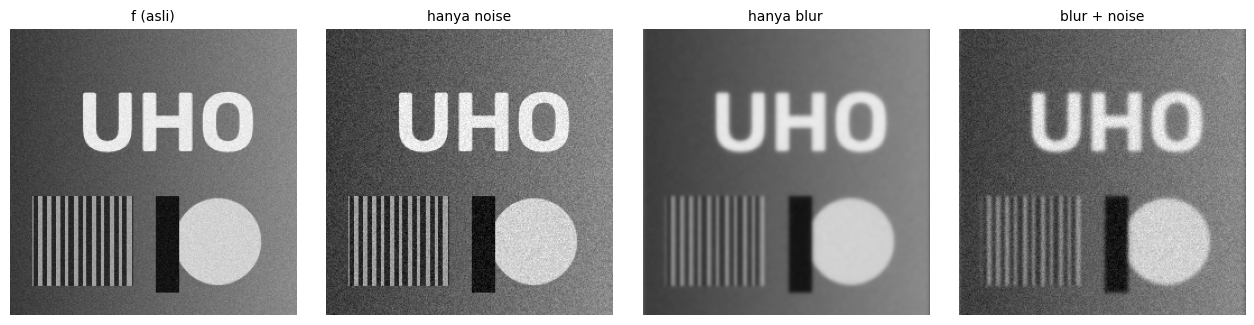

In [39]:
f = muat_citra()
M, N = f.shape

U, V = frek_terpusat(M, N)
H = np.exp(-0.0025 * (U**2 + V**2) ** (5 / 6))        # turbulensi atmosfer

hanya_noise = degradasi(f, np.ones((M, N)), sigma=10)  # H = 1 → tanpa blur
hanya_blur  = degradasi(f, H, sigma=0)
keduanya    = degradasi(f, H, sigma=10)

for nama, g in [('hanya noise', hanya_noise), ('hanya blur', hanya_blur), ('blur + noise', keduanya)]:
    print(f'{nama:13s} PSNR = {psnr(f, g):5.2f} dB')

tampilkan([f, hanya_noise, hanya_blur, keduanya],
          ['f (asli)', 'hanya noise', 'hanya blur', 'blur + noise'])

## Mengestimasi H dengan eksperimen: rekam sebuah impuls (slide 8)

Respons sistem terhadap impuls = PSF h(x,y); DFT-nya = H(u,v).

True


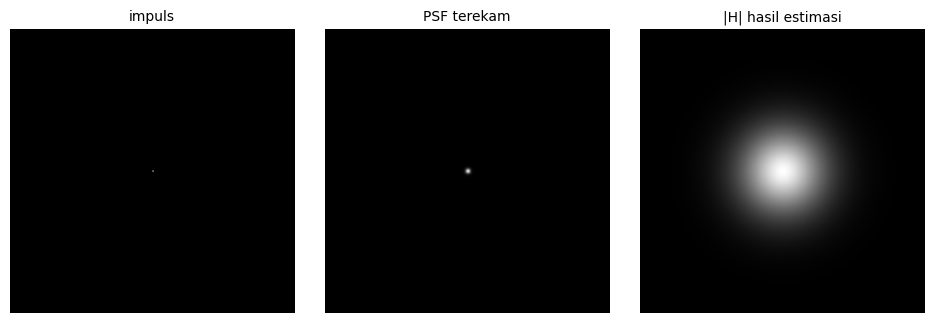

In [40]:
M = N = 256
U, V = frek_terpusat(M, N)
H_sistem = np.exp(-0.0025 * (U**2 + V**2) ** (5 / 6))   # sistem "tak diketahui"

impuls = np.zeros((M, N))
impuls[M // 2, N // 2] = 1.0                            # titik cahaya terang

psf = degradasi(impuls, H_sistem)                        # yang terekam kamera

# Estimasi H dari PSF: DFT dari psf (geser pusat impuls ke (0,0) dulu)
H_est = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(psf)))
print(np.allclose(H_est, H_sistem))                      # True

tampilkan([impuls, psf, np.abs(H_est)], ['impuls', 'PSF terekam', '|H| hasil estimasi'],
          rentang=None)

---
# Bagian 02 · Imaging difraksi sirkular

## Imaging difraksi sirkular (lensa beraperture lingkaran) (slide 11)

OTF lensa terbatas-difraksi (cahaya inkoheren), ρ = D(u,v)/ρc:
`H(ρ) = (2/π) · [arccos ρ − ρ·√(1 − ρ²)]   untuk ρ ≤ 1,   0 untuk ρ > 1`  
PSF-nya adalah cakram Airy.

H di DC = 1.0 | H di ρc = 0.0
PSF selalu ≥ 0? True | jumlah PSF = 1.0


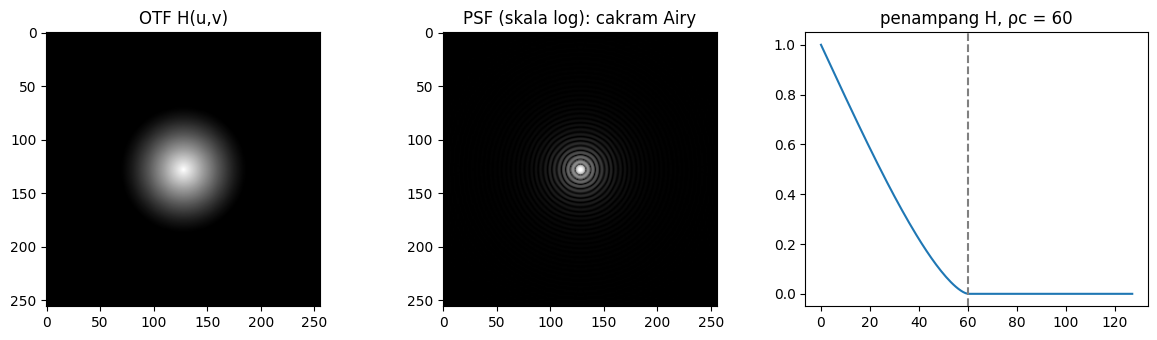

In [41]:
def h_sirkular(M, N, rho_c):
    """OTF difraksi aperture lingkaran dengan frekuensi potong ρc."""
    rho = np.clip(jarak(M, N) / rho_c, 0, 1)
    return (2 / np.pi) * (np.arccos(rho) - rho * np.sqrt(1 - rho**2))


M = N = 256
H = h_sirkular(M, N, rho_c=60)
print('H di DC =', H[M // 2, N // 2], '| H di ρc =', H[M // 2, N // 2 + 60])   # 1.0 | 0.0

psf = np.real(np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(H))))       # cakram Airy
print('PSF selalu ≥ 0?', psf.min() >= 0, '| jumlah PSF =', round(psf.sum(), 6))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].imshow(H, cmap='gray'); ax[0].set_title('OTF H(u,v)')
ax[1].imshow(np.log1p(psf / psf.max() * 1e4), cmap='gray'); ax[1].set_title('PSF (skala log): cakram Airy')
ax[2].plot(H[M // 2, N // 2:]); ax[2].axvline(60, ls='--', c='gray'); ax[2].set_title('penampang H, ρc = 60')
plt.tight_layout(); plt.show()

## Efek difraksi untuk berbagai ρc (slide 12)

ρc kecil (aperture kecil / jarak jauh) → lebih buram. Frekuensi di atas ρc
HILANG sama sekali (H = 0) — tidak bisa dikembalikan oleh filter apa pun.

ρc = 90: PSNR = 24.44 dB
ρc = 60: PSNR = 22.54 dB
ρc = 30: PSNR = 19.74 dB


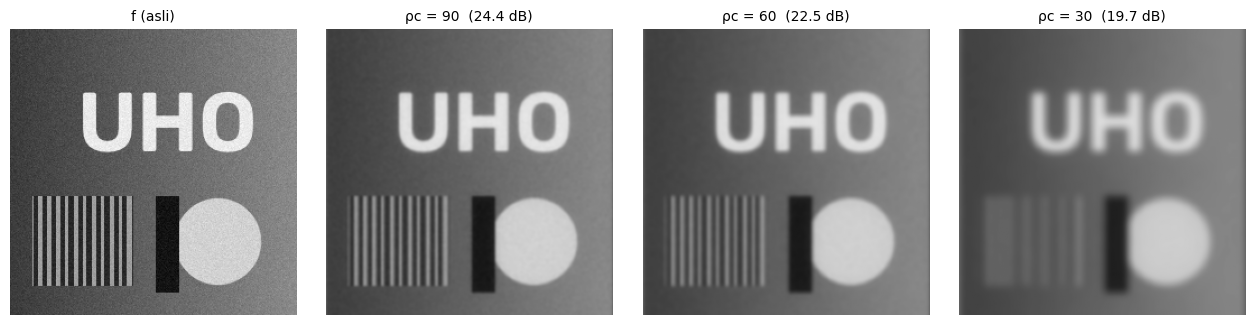

In [42]:
f = muat_citra()
M, N = f.shape

hasil, judul = [f], ['f (asli)']
for rho_c in [90, 60, 30]:
    g = degradasi(f, h_sirkular(M, N, rho_c))
    hasil.append(g)
    judul.append(f'ρc = {rho_c}  ({psnr(f, g):.1f} dB)')
    print(f'ρc = {rho_c:2d}: PSNR = {psnr(f, g):.2f} dB')

tampilkan(hasil, judul)

---
# Bagian 03 · Image motion blur

## Model image motion blur (gerak lurus beraturan selama waktu buka T) (slide 15)

`H(u,v) = T / (π(ua + vb)) · sin(π(ua + vb)) · e^(−jπ(ua + vb))`  
Total pergeseran: a·M piksel ke bawah dan b·N piksel ke kanan.

PSNR = 15.81 dB
kolom dengan |H| = 0 (baris tengah): [-120 -110 -100  -90  -80  -70]


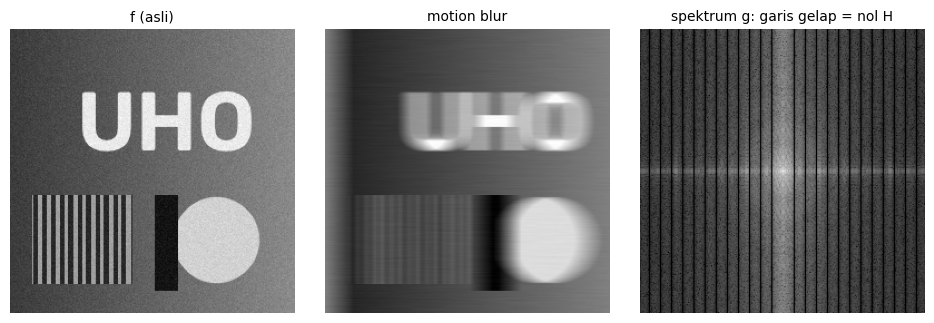

In [43]:
def h_motion(M, N, a=0.0, b=0.1, T=1.0):
    """Fungsi degradasi motion blur (terpusat). Tangani π(ua+vb) = 0 → H = T."""
    U, V = frek_terpusat(M, N)
    s = np.pi * (U * a + V * b)
    s_aman = np.where(s == 0, 1.0, s)                # hindari pembagian nol
    H = T * np.sin(s_aman) / s_aman * np.exp(-1j * s)
    return np.where(s == 0, T, H)


f = muat_citra()
M, N = f.shape
H = h_motion(M, N, a=0.0, b=0.1)                 # gerak horizontal ≈ 25,6 px
g = degradasi(f, H)

print(f'PSNR = {psnr(f, g):.2f} dB')
print('kolom dengan |H| = 0 (baris tengah):', np.where(np.abs(H[M // 2]) < 1e-9)[0][:6] - N // 2)

tampilkan([f, g, spektrum(g)], ['f (asli)', 'motion blur', 'spektrum g: garis gelap = nol H'],
          rentang=None)

## Motion blur = rata-rata citra yang bergeser (slide 16)

Model frekuensi setara dengan merata-ratakan ±26 salinan citra yang digeser 1 px.
Jarak antar-garis nol pada spektrum mengungkap panjang & arah gerak.

RMSE frekuensi vs spasial = 0.84 (skala 0–255)
jarak antar-nol = 10 kolom → panjang gerak ≈ N / 10 = 25.6 px


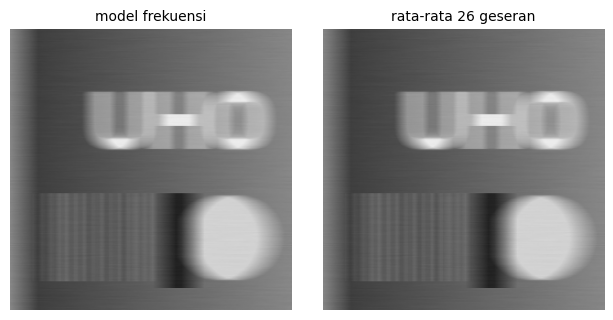

In [44]:
f = muat_citra()
M, N = f.shape
b = 0.1

g_frek = degradasi(f, h_motion(M, N, a=0.0, b=b))

# Versi spasial: rata-rata 26 salinan yang digeser 0..25 piksel ke kanan
g_spasial = sum(np.roll(f, s, axis=1) for s in range(26)) / 26
rmse = np.sqrt(np.mean((g_frek - g_spasial) ** 2))
print(f'RMSE frekuensi vs spasial = {rmse:.2f} (skala 0–255)')    # kecil → setara

# Membaca spektrum: nol H berjarak 1/b kolom → panjang gerak = N·b piksel
nol = np.where(np.abs(h_motion(M, N, 0, b)[M // 2]) < 1e-9)[0]
jarak_nol = np.diff(nol)[0]
print(f'jarak antar-nol = {jarak_nol} kolom → panjang gerak ≈ N / {jarak_nol} = {N / jarak_nol:.1f} px')

tampilkan([g_frek, g_spasial], ['model frekuensi', 'rata-rata 26 geseran'])

---
# Bagian 04 · Photographic recording model

*Sel berikut memakai fungsi `wiener()` dari slide 23 — didefinisikan di sini lebih dulu.*

In [45]:
def wiener(H, K):
    """Filter Wiener dengan konstanta K (dibahas di slide 23)."""
    return np.conj(H) / (np.abs(H) ** 2 + K)

## Photographic recording model (slide 19)

Film merespons eksposur E secara NON-LINEAR (kurva H&D):
`D = γ · log10(E) + D_off`  
Model lengkap: g = s[h ⋆ f] + η. Karena s non-linear, sistem tidak lagi LSI →
linearisasi dulu (balik kurva H&D), baru restorasi linear.

langsung pada D    : 13.75 dB
linearisasi dahulu : 25.12 dB


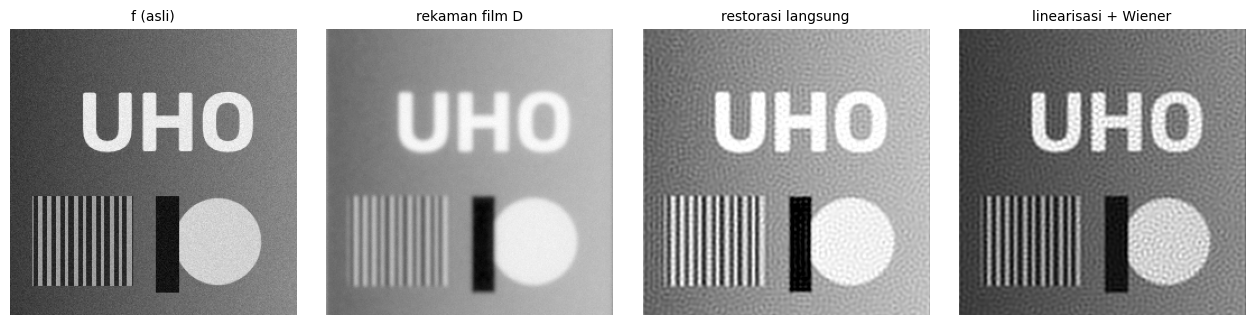

In [46]:
f = muat_citra()
M, N = f.shape
gamma, D_off = 1.2, 2.0
H = h_sirkular(M, N, rho_c=60)

# 1) Rekaman: blur optik → eksposur E → densitas film D (+ noise butiran film)
E = 0.02 + 0.98 * degradasi(f / 255.0, H)               # eksposur 0,02 … 1
D = gamma * np.log10(np.clip(E, 1e-3, None)) + D_off      # kurva H&D (daerah linear)
D = D + np.random.default_rng(1).normal(0, 0.01, D.shape)

# 2a) Salah: restorasi langsung pada D (yang tidak linear)
D01 = (D - D.min()) / (D.max() - D.min())
salah = np.clip(restorasi(D01, wiener(H, 1e-3)), 0, 1) * 255

# 2b) Benar: linearisasi (balik kurva H&D) → restorasi
E_lin = 10 ** ((D - D_off) / gamma)
f_lin = (E_lin - 0.02) / 0.98
benar = np.clip(restorasi(f_lin, wiener(H, 1e-3)), 0, 1) * 255

print(f'langsung pada D    : {psnr(f, salah):.2f} dB')
print(f'linearisasi dahulu : {psnr(f, benar):.2f} dB')

tampilkan([f, D01 * 255, salah, benar], ['f (asli)', 'rekaman film D', 'restorasi langsung', 'linearisasi + Wiener'])

---
# Bagian 05 · Restorasi: inverse & Wiener

## Filter inverse (slide 22)

`F̂ = G / H = F + N / H`  
Di mana |H| ≈ 0, suku N/H meledak → batasi ke lingkaran berjari-jari D0.

σ = 0: g = 15.81 dB | inverse penuh = 27.04 dB
σ = 2: g = 15.80 dB | inverse penuh = 11.16 dB
inverse D0 = 20: 20.03 dB
inverse D0 = 40: 22.93 dB
inverse D0 = 70: 20.49 dB


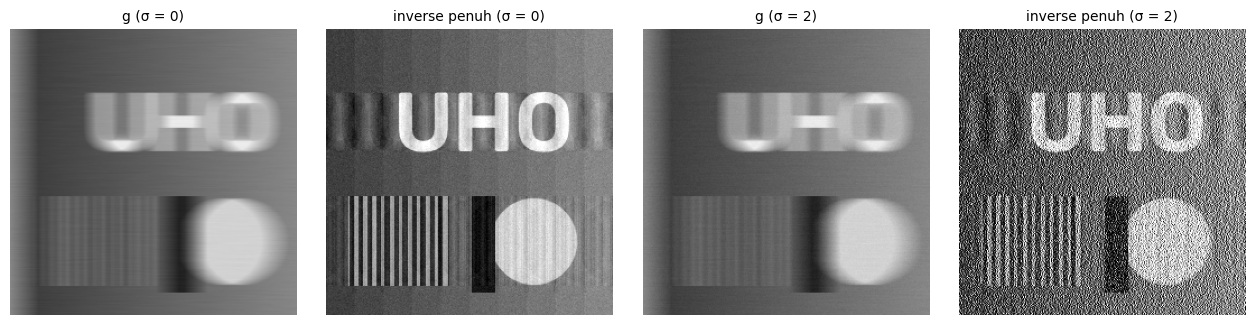

In [47]:
def invers(H, eps=1e-3, D0=None):
    """R = 1/H di tempat |H| > eps (selain itu 0); opsional dibatasi D ≤ D0."""
    aman = np.abs(H) > eps
    R = np.where(aman, 1 / np.where(aman, H, 1), 0)
    if D0 is not None:
        R = R * (jarak(*H.shape) <= D0)
    return R


f = muat_citra()
M, N = f.shape
H = h_motion(M, N, a=0.0, b=0.1)

hasil, judul = [], []
for sigma in [0, 2]:
    g = degradasi(f, H, sigma)
    f_inv = np.clip(restorasi(g, invers(H)), 0, 255)
    print(f'σ = {sigma}: g = {psnr(f, g):.2f} dB | inverse penuh = {psnr(f, f_inv):.2f} dB')
    hasil += [g, f_inv]; judul += [f'g (σ = {sigma})', f'inverse penuh (σ = {sigma})']

for D0 in [20, 40, 70]:                        # batasi radius (σ = 2)
    f_r = np.clip(restorasi(g, invers(H, D0=D0)), 0, 255)
    print(f'inverse D0 = {D0}: {psnr(f, f_r):.2f} dB')

tampilkan(hasil, judul)

## Filter Wiener (minimum mean square error) (slide 23)

`F̂ = [ H* / (|H|² + K) ] · G`  
K ≈ rasio daya noise / daya sinyal. K = 0 → kembali menjadi filter inverse.

K = 0.0001: 13.61 dB
K = 0.003: 21.47 dB
K = 0.1: 18.49 dB


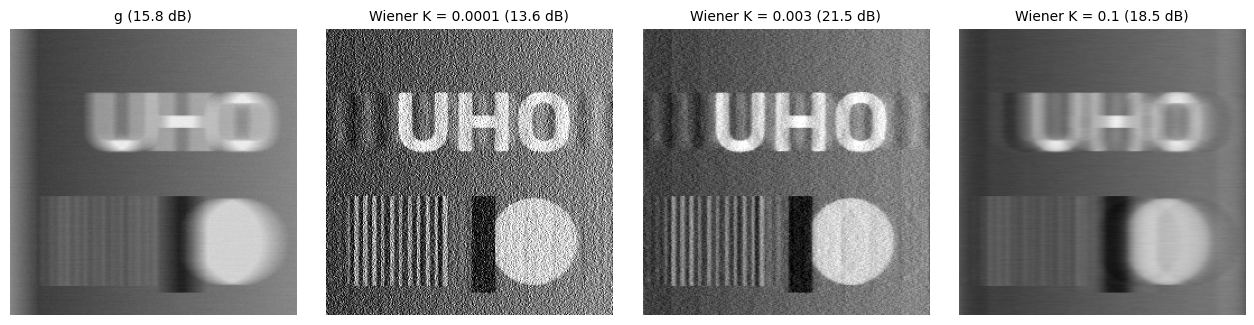

In [48]:
def wiener(H, K):
    """Filter Wiener dengan konstanta K."""
    return np.conj(H) / (np.abs(H) ** 2 + K)


f = muat_citra()
M, N = f.shape
H = h_motion(M, N, a=0.0, b=0.1)
g = degradasi(f, H, sigma=2)

hasil, judul = [g], [f'g ({psnr(f, g):.1f} dB)']
for K in [1e-4, 3e-3, 1e-1]:
    f_w = np.clip(restorasi(g, wiener(H, K)), 0, 255)
    print(f'K = {K:g}: {psnr(f, f_w):.2f} dB')
    hasil.append(f_w); judul.append(f'Wiener K = {K:g} ({psnr(f, f_w):.1f} dB)')

tampilkan(hasil, judul)

## Perbandingan inverse vs Wiener pada dua jenis degradasi (σ = 2) (slide 24)

difraksi ρc = 60
   terdegradasi       22.49 dB
   inverse penuh      11.17 dB
   inverse D0 = 40    25.55 dB
   Wiener K = 0,003   25.99 dB


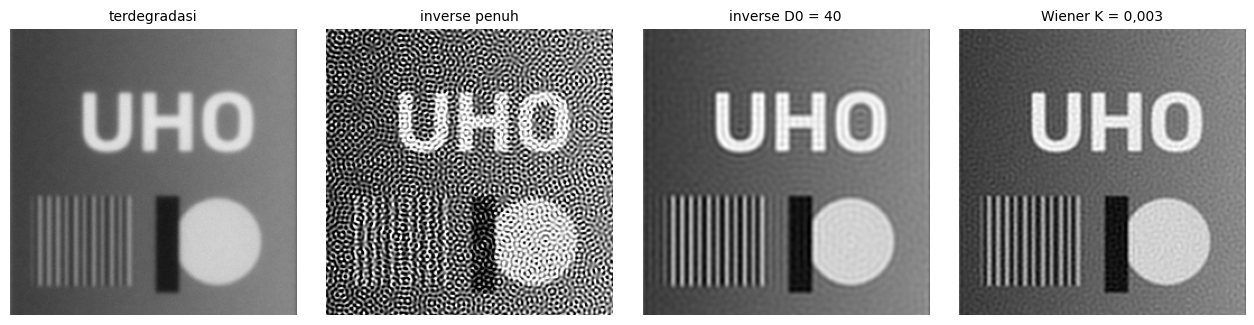

motion b = 0,1
   terdegradasi       15.80 dB
   inverse penuh      11.16 dB
   inverse D0 = 40    22.93 dB
   Wiener K = 0,003   21.47 dB


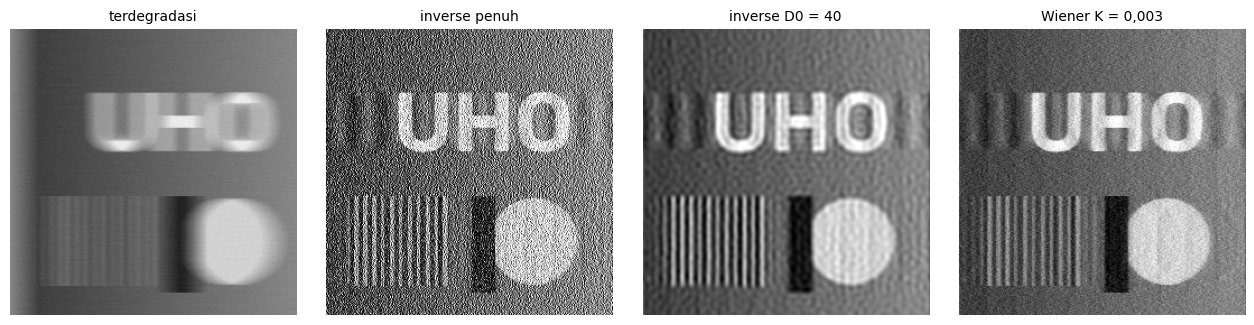

In [49]:
f = muat_citra()
M, N = f.shape

kasus = {'difraksi ρc = 60': h_sirkular(M, N, 60),
         'motion b = 0,1': h_motion(M, N, a=0.0, b=0.1)}

for nama, H in kasus.items():
    g = degradasi(f, H, sigma=2)
    hasil = {'terdegradasi': g,
             'inverse penuh': restorasi(g, invers(H)),
             'inverse D0 = 40': restorasi(g, invers(H, D0=40)),
             'Wiener K = 0,003': restorasi(g, wiener(H, 3e-3))}
    print(nama)
    for k, v in hasil.items():
        print(f'   {k:17s} {psnr(f, np.clip(v, 0, 255)):6.2f} dB')
    tampilkan([np.clip(v, 0, 255) for v in hasil.values()], list(hasil))

## Memilih K: sapu nilai K dan amati PSNR (slide 25)

Dalam praktik citra asli f tidak diketahui → K dipilih secara visual,
atau diperkirakan dari daya noise ÷ daya sinyal.

K terbaik ≈ 0.0040 → 21.65 dB
perkiraan σ²/rata-rata(f²) = 0.00025


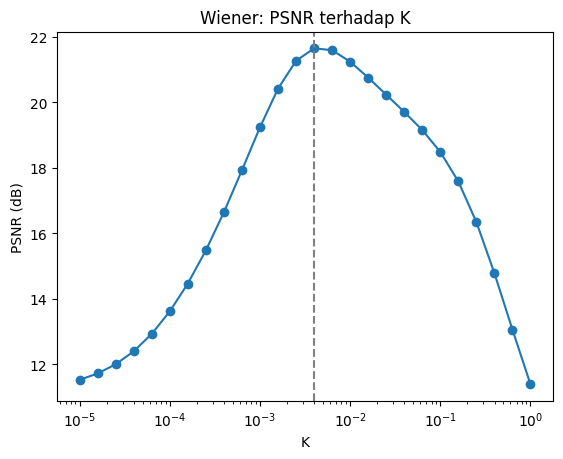

In [50]:
f = muat_citra()
M, N = f.shape
H = h_motion(M, N, a=0.0, b=0.1)
g = degradasi(f, H, sigma=2)

daftar_K = np.logspace(-5, 0, 26)                   # 1e-5 … 1
nilai = [psnr(f, np.clip(restorasi(g, wiener(H, K)), 0, 255)) for K in daftar_K]

terbaik = daftar_K[int(np.argmax(nilai))]
print(f'K terbaik ≈ {terbaik:.4f} → {max(nilai):.2f} dB')

# Perkiraan kasar K = daya noise / daya sinyal
K_kira = 2**2 / np.mean(f ** 2)
print(f'perkiraan σ²/rata-rata(f²) = {K_kira:.5f}')

plt.semilogx(daftar_K, nilai, marker='o')
plt.axvline(terbaik, ls='--', c='gray')
plt.xlabel('K'); plt.ylabel('PSNR (dB)'); plt.title('Wiener: PSNR terhadap K'); plt.show()

---
# Praktikum (slide 28)
Kerjakan di sel kosong di bawah setiap soal. Tambahkan sel teks untuk menjelaskan hasil Anda.

**1.** Ulangi slide 12 untuk ρc = 10…100. Buat grafik PSNR terhadap ρc dan jelaskan bentuknya.

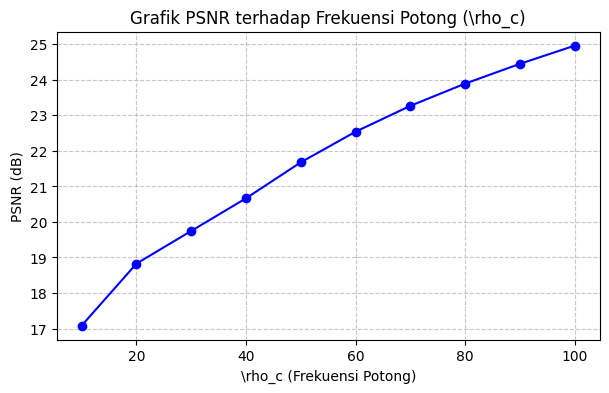

Penjelasan:
Makin besar nilai rho_c (aperture makin besar), makin tinggi nilai PSNR-nya yang menunjukkan citra semakin mirip dengan aslinya (degradasi blur semakin berkurang). Hubungan ini terlihat non-linear, di mana peningkatan PSNR sangat pesat pada rentang awal (rho_c = 10 ke 40) lalu mulai melandai setelahnya karena frekuensi tinggi yang krusial bagi ketajaman detail citra sudah terselamatkan.


In [51]:
#JAWABAN SOAL NOMOR 1
# 1. Ambil citra asli
f = muat_citra()
M, N = f.shape

# 2. Sapu nilai rho_c dari 10 sampai 100
rho_c_values = np.arange(10, 101, 10)
psnr_values = []

for rc in rho_c_values:
    H = h_sirkular(M, N, rho_c=rc)
    g = degradasi(f, H, sigma=0)  # tanpa noise
    psnr_values.append(psnr(f, g))

# 3. Tampilkan grafik PSNR vs rho_c
plt.figure(figsize=(7, 4))
plt.plot(rho_c_values, psnr_values, marker='o', color='b', linestyle='-')
plt.title('Grafik PSNR terhadap Frekuensi Potong (\\rho_c)', fontsize=12)
plt.xlabel('\\rho_c (Frekuensi Potong)', fontsize=10)
plt.ylabel('PSNR (dB)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Penjelasan bentuk grafik
print("Penjelasan:\nMakin besar nilai rho_c (aperture makin besar), makin tinggi nilai PSNR-nya yang menunjukkan citra semakin mirip dengan aslinya (degradasi blur semakin berkurang). Hubungan ini terlihat non-linear, di mana peningkatan PSNR sangat pesat pada rentang awal (rho_c = 10 ke 40) lalu mulai melandai setelahnya karena frekuensi tinggi yang krusial bagi ketajaman detail citra sudah terselamatkan.")

**2.** Buat motion blur **diagonal** (a = b = 0,05). Tampilkan spektrumnya dan tunjukkan arah garis nol.

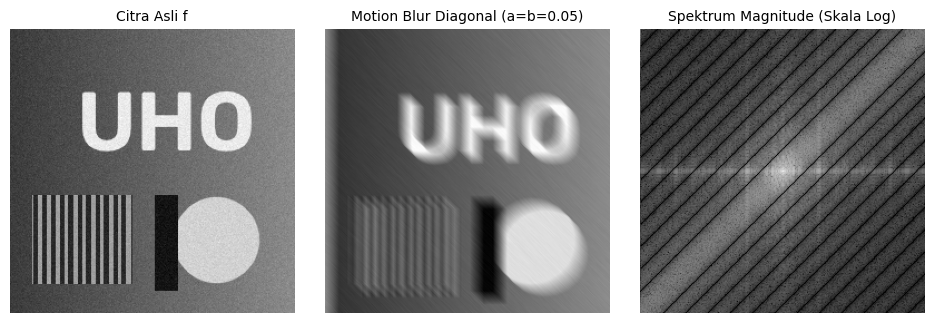

Penjelasan Arah Garis Nol:
Garis-garis gelap (nilai nol pada H) di spektrum di atas berorientasi tegak lurus (diagonal arah sebaliknya) terhadap arah gerakan blur spasial. Karena gerakan terjadi secara diagonal dari kiri-atas ke kanan-bawah (arah a = b = 0.05), garis-garis nol pada spektrum terbentuk tegak lurus memotong sumbu diagonal tersebut (dari kiri-bawah ke kanan-atas).


In [52]:
#JAWABAN SOAL NOMOR 2
# Buat motion blur diagonal dengan a = b = 0.05
f = muat_citra()
M, N = f.shape
a = b = 0.05
H_diagonal = h_motion(M, N, a=a, b=b)
g_diagonal = degradasi(f, H_diagonal, sigma=0)

# Tampilkan citra dan spektrumnya secara visual
tampilkan([f, g_diagonal, spektrum(g_diagonal)],
          ['Citra Asli f', 'Motion Blur Diagonal (a=b=0.05)', 'Spektrum Magnitude (Skala Log)'],
          rentang=None)

print("Penjelasan Arah Garis Nol:\nGaris-garis gelap (nilai nol pada H) di spektrum di atas berorientasi tegak lurus (diagonal arah sebaliknya) terhadap arah gerakan blur spasial. Karena gerakan terjadi secara diagonal dari kiri-atas ke kanan-bawah (arah a = b = 0.05), garis-garis nol pada spektrum terbentuk tegak lurus memotong sumbu diagonal tersebut (dari kiri-bawah ke kanan-atas).")

**3.** Restorasi motion blur dengan σ = 0, 1, 2, 5: bandingkan inverse terbatas dan Wiener (K terbaik) dalam satu tabel.

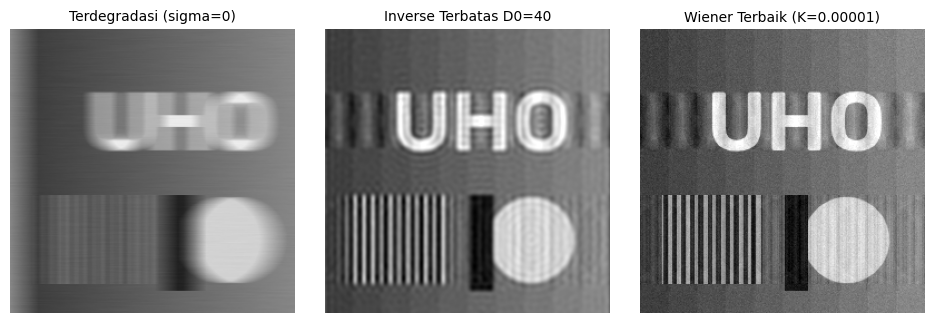

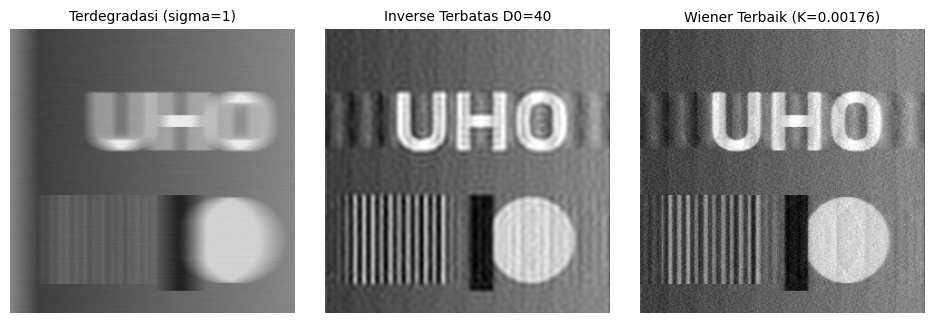

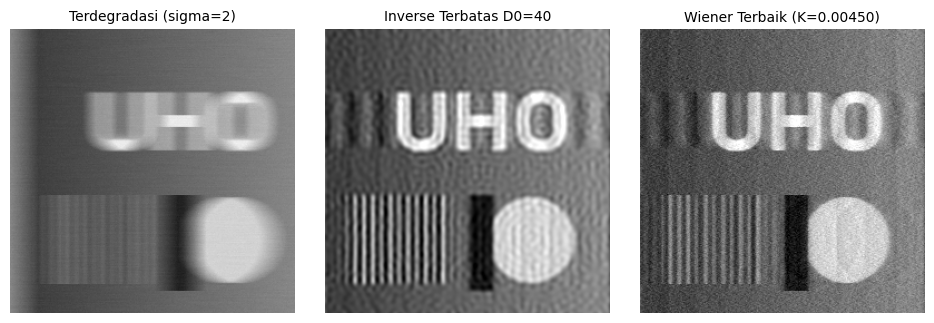

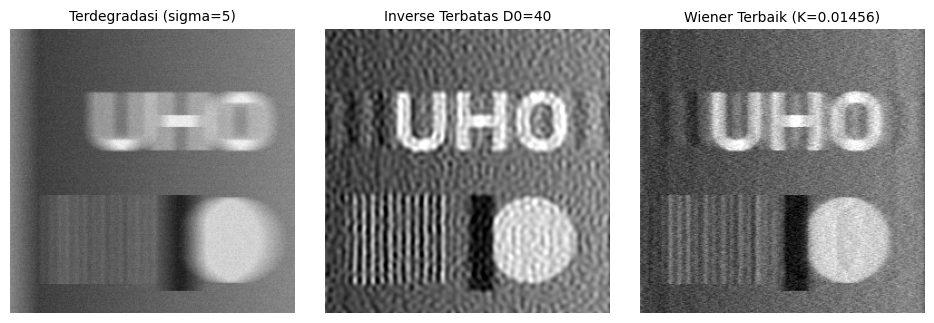

,Noise (sigma),PSNR Terdegradasi (dB),PSNR Inverse D0=40 (dB),PSNR Wiener Terbaik (dB),K Terbaik
0,0,15.81,23.49,27.03,0.00001
1,1,15.81,23.35,23.06,0.00176
2,2,15.80,22.94,21.65,0.00450
3,5,15.75,20.86,19.97,0.01456



Kesimpulan:
Pada kondisi tanpa noise (sigma = 0), Inverse terbatas memberikan hasil yang cukup baik namun Wiener tetap unggul dengan memilih K sangat kecil mendekati 0. Ketika noise meningkat (sigma = 1, 2, 5), performa filter Inverse menurun drastis karena noise di luar radius D0 tidak terfilter sempurna, sedangkan Wiener otomatis menyesuaikan nilai K menjadi lebih besar untuk meredam amplifikasi noise tersebut sehingga hasil restorasinya jauh lebih stabil dan superior.


In [53]:
#JAWABAN SOAL NOMOR 3
f = muat_citra()
M, N = f.shape
H = h_motion(M, N, a=0.0, b=0.1)  # model degradasi motion blur horizontal

sigmas = [0, 1, 2, 5]
daftar_K = np.logspace(-5, 0, 50)  # kandidat K untuk Wiener

baris_tabel = []

for sigma in sigmas:
    # Buat citra terdegradasi
    g = degradasi(f, H, sigma=sigma, seed=42)
    psnr_degradasi = psnr(f, g)

    # 1. Restorasi dengan Inverse Terbatas (D0 = 40)
    f_inv_terbatas = np.clip(restorasi(g, invers(H, D0=40)), 0, 255)
    psnr_inv = psnr(f, f_inv_terbatas)

    # 2. Restorasi dengan Wiener (Cari K terbaik berdasarkan PSNR)
    best_psnr_wiener = -1
    best_K = 0
    for K in daftar_K:
        f_w = np.clip(restorasi(g, wiener(H, K)), 0, 255)
        nilai_psnr = psnr(f, f_w)
        if nilai_psnr > best_psnr_wiener:
            best_psnr_wiener = nilai_psnr
            best_K = K

    baris_tabel.append({
        'Noise (sigma)': sigma,
        'PSNR Terdegradasi (dB)': f"{psnr_degradasi:.2f}",
        'PSNR Inverse D0=40 (dB)': f"{psnr_inv:.2f}",
        'PSNR Wiener Terbaik (dB)': f"{best_psnr_wiener:.2f}",
        'K Terbaik': f"{best_K:.5f}"
    })

    # Tampilkan perbandingan visual hasil restorasi untuk setiap sigma
    tampilkan([g, f_inv_terbatas, np.clip(restorasi(g, wiener(H, best_K)), 0, 255)],
              [f'Terdegradasi (sigma={sigma})', f'Inverse Terbatas D0=40', f'Wiener Terbaik (K={best_K:.5f})'])

# Tampilkan hasil dalam bentuk DataFrame / Tabel
df_hasil = pd.DataFrame(baris_tabel)
display(df_hasil)

print("\nKesimpulan:\nPada kondisi tanpa noise (sigma = 0), Inverse terbatas memberikan hasil yang cukup baik namun Wiener tetap unggul dengan memilih K sangat kecil mendekati 0. Ketika noise meningkat (sigma = 1, 2, 5), performa filter Inverse menurun drastis karena noise di luar radius D0 tidak terfilter sempurna, sedangkan Wiener otomatis menyesuaikan nilai K menjadi lebih besar untuk meredam amplifikasi noise tersebut sehingga hasil restorasinya jauh lebih stabil dan superior.")

**4.** Ubah γ pada slide 19 menjadi 0,6 dan 2,0. Apakah linearisasi tetap penting?

In [54]:
# Jawaban soal 4

**5.** **Foto nyata:** potret objek diam sambil menggerakkan ponsel (unggah dengan `PAKAI_CITRA_SENDIRI = True`). Tebak arah & panjang gerak dari spektrum, lalu restorasi dengan Wiener (siapkan tepi: `np.pad(..., mode='reflect')`).

In [55]:
# Jawaban soal 5